# Titanic Survival Prediction

Predicting whether a passenger survived from sex, class, age, family aboard and fare, using the `titanic3` dataset (1,309 passengers).

**Approach**
1. Explore how each feature relates to survival
2. Prepare features, filling in missing ages instead of dropping those passengers
3. Compare a no-skill baseline, Naive Bayes, logistic regression, gradient boosting and a small neural network using 5-fold cross-validation, so the comparison doesn't hinge on one lucky train/test split

## 1. Load and clean the data

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

RANDOM_STATE = 0

data = pd.read_csv('titanic3.csv')
data = data.replace('?', np.nan)
data = data.astype({"age": np.float64, "fare": np.float64})
data.shape

(1309, 14)

## 2. Explore

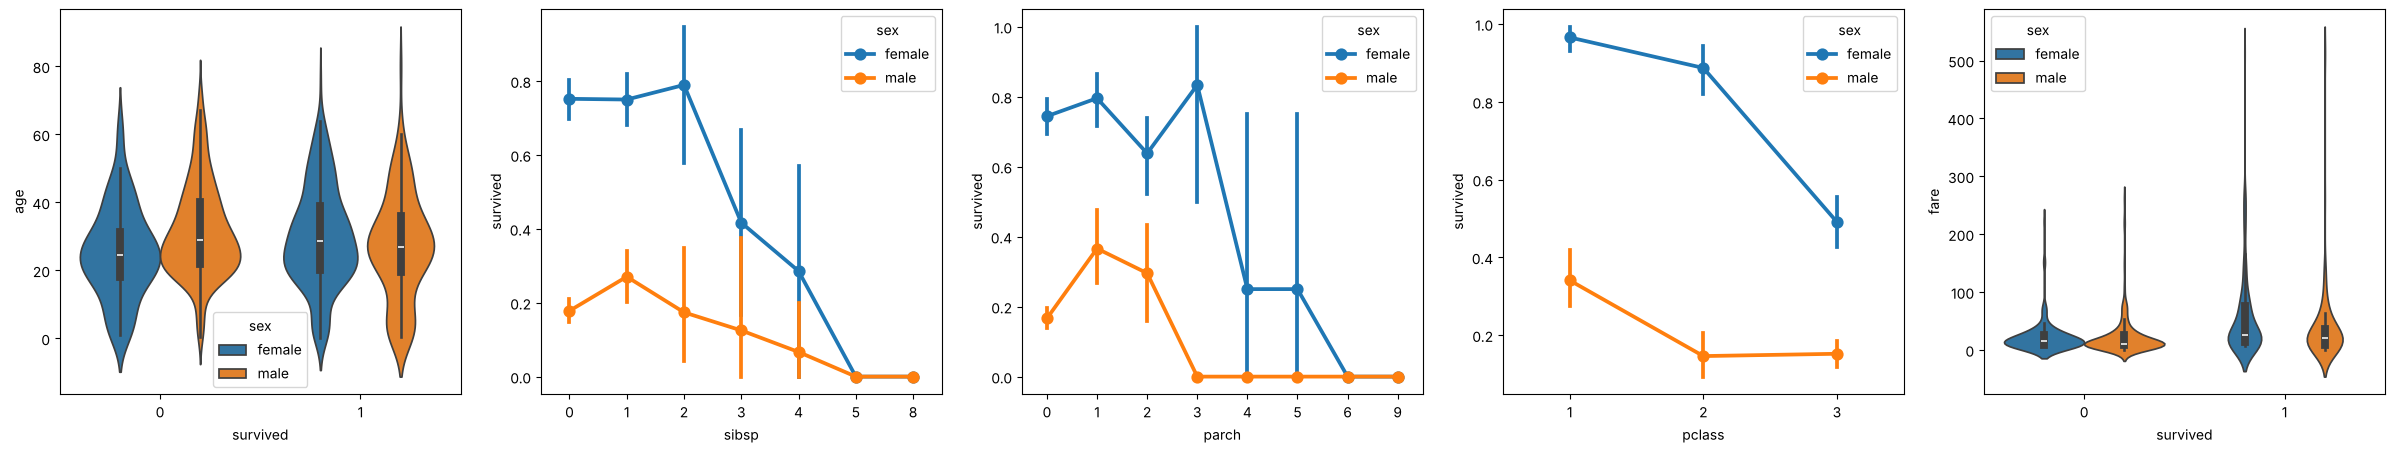

In [2]:
fig, axs = plt.subplots(ncols=5, figsize=(30, 5))
sns.violinplot(x="survived", y="age", hue="sex", data=data, ax=axs[0])
sns.pointplot(x="sibsp", y="survived", hue="sex", data=data, ax=axs[1])
sns.pointplot(x="parch", y="survived", hue="sex", data=data, ax=axs[2])
sns.pointplot(x="pclass", y="survived", hue="sex", data=data, ax=axs[3])
sns.violinplot(x="survived", y="fare", hue="sex", data=data, ax=axs[4])
plt.show()

## 3. Prepare features

`relatives` flags anyone travelling with family. `sex` is encoded as 1 = male, 0 = female.

In [3]:
data['sex'] = data['sex'].map({'male': 1, 'female': 0})
data['relatives'] = ((data['sibsp'] + data['parch']) > 0).astype(int)

data.corr(numeric_only=True).abs()[["survived"]].sort_values("survived", ascending=False)

,survived
survived,1.000000
sex,0.528693
pclass,0.312469
fare,0.244265
relatives,0.201719
parch,0.082660
age,0.055512
sibsp,0.027825
body,NaN


About 20% of passengers have no recorded age. The original version dropped them with `dropna()`; here missing values are filled with the median inside the model pipeline instead, so every passenger is used and the median is learned only from training data in each fold (no leakage from the test fold).

In [4]:
FEATURES = ['sex', 'pclass', 'age', 'relatives', 'fare']

X = data[FEATURES]
y = data['survived'].astype(int)

X.isna().sum()

sex            0
pclass         0
age          263
relatives      0
fare           1
dtype: int64

## 4. Compare models with 5-fold cross-validation

The **baseline** always predicts the most common outcome (did not survive). Any useful model has to beat it.

In [5]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_model(estimator):
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), estimator)

candidates = {
    'Baseline (always "died")': DummyClassifier(strategy='most_frequent'),
    'Naive Bayes': GaussianNB(),
    'Logistic regression': LogisticRegression(),
    'Gradient boosting': HistGradientBoostingClassifier(max_depth=3, random_state=RANDOM_STATE),
}

results = {}
for name, estimator in candidates.items():
    results[name] = cross_val_score(make_model(estimator), X, y, cv=cv, scoring='accuracy')

### Neural network

The same Keras network as the original (5 → 5 → 1), trained and scored on the same five folds.

In [6]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # hide TensorFlow startup logs

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, Input

def build_network():
    network = Sequential([
        Input(shape=(len(FEATURES),)),
        Dense(5, kernel_initializer='uniform', activation='relu'),
        Dense(5, kernel_initializer='uniform', activation='relu'),
        Dense(1, kernel_initializer='uniform', activation='sigmoid'),
    ])
    network.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return network

nn_scores = []
for fold, (train_idx, test_idx) in enumerate(cv.split(X, y)):
    tf.keras.utils.set_random_seed(RANDOM_STATE + fold)
    prep = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
    X_train = prep.fit_transform(X.iloc[train_idx])
    X_test = prep.transform(X.iloc[test_idx])

    network = build_network()
    network.fit(X_train, y.iloc[train_idx], batch_size=32, epochs=50, verbose=0)
    _, accuracy = network.evaluate(X_test, y.iloc[test_idx], verbose=0)
    nn_scores.append(accuracy)

results['Neural network (Keras)'] = np.array(nn_scores)
build_network().summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 5)              │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 5)              │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66 (264.00 B)

 Trainable params: 66 (264.00 B)

 Non-trainable params: 0 (0.00 B)

## 5. Results

In [7]:
summary = pd.DataFrame({
    'mean accuracy': {k: v.mean() for k, v in results.items()},
    'std across folds': {k: v.std() for k, v in results.items()},
}).sort_values('mean accuracy', ascending=False)

summary.map(lambda v: f"{v:.1%}")

,mean accuracy,std across folds
Gradient boosting,80.1%,1.1%
Neural network (Keras),79.5%,0.9%
Logistic regression,78.6%,1.6%
Naive Bayes,75.8%,1.8%
"Baseline (always ""died"")",61.8%,0.1%


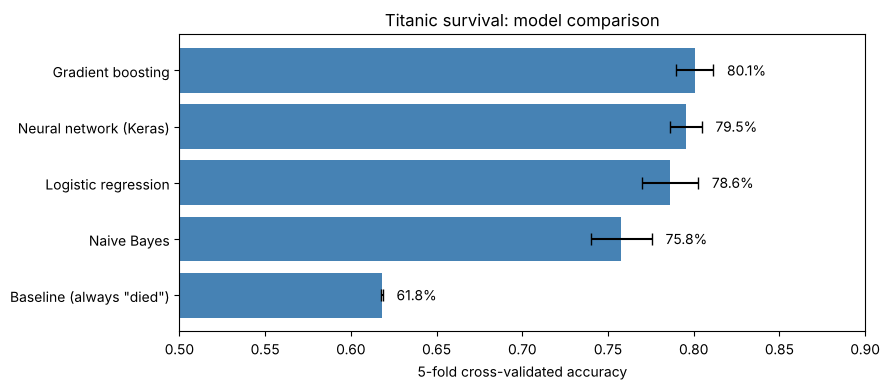

In [8]:
order = summary.index[::-1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(order, summary.loc[order, 'mean accuracy'],
        xerr=summary.loc[order, 'std across folds'], color='steelblue', capsize=4)
ax.set_xlim(0.5, 0.9)
ax.set_xlabel('5-fold cross-validated accuracy')
ax.set_title('Titanic survival: model comparison')
for i, name in enumerate(order):
    mean, spread = summary.loc[name, 'mean accuracy'], summary.loc[name, 'std across folds']
    ax.text(mean + spread + 0.008, i, f'{mean:.1%}', va='center')
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=120)
plt.show()

## Takeaways

- Every model clears the ~62% baseline by a wide margin. Sex and passenger class carry most of the signal.
- The top three models land within about 1.5 points of each other (78.6–80.1%), which is about the size of the fold-to-fold spread, so none is a clear winner. The original notebook's big neural-network advantage (79.9% vs 74.6% for Naive Bayes) came from a single 80/20 split.
- Gradient boosting matches or beats the neural network here with far less tuning, which is typical for small tabular datasets.

**Possible next steps:** extract the title (Mr, Mrs, Miss, Master) from `name` as a feature and use it to impute age more accurately; tune gradient boosting with a grid search.